# Exploration des données SINERT

Ce notebook charge les exports du concentrateur SINERT, construit l'horodatage, supprime les doublons de frontière entre fichiers et vérifie la qualité des données.

Les fichiers bruts ne sont jamais modifiés.

In [1]:
from pathlib import Path
import sys

# Retrouver la racine du projet même si le notebook est lancé depuis notebooks/.
PROJECT_ROOT = Path.cwd()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_sinert_measurements, list_data_files
from src.preprocessing import (
    add_estimated_power_factor,
    combine_date_and_time,
    remove_duplicates,
)

RAW_DIR = PROJECT_ROOT / 'data' / 'raw' / 'SINERT_DATA_CONCENTRATOR'
print(f'Racine du projet : {PROJECT_ROOT}')
print(f'Dossier des données : {RAW_DIR}')
print(f'Fichiers détectés : {len(list_data_files(RAW_DIR))}')

Racine du projet : C:\Évaluation approfondie2
Dossier des données : C:\Évaluation approfondie2\data\raw\SINERT_DATA_CONCENTRATOR
Fichiers détectés : 714


## Chargement des mesures principales

On ne charge que les mesures nécessaires au projet : énergie active, énergie réactive, puissances maximales et facteur de puissance.

In [2]:
df = load_sinert_measurements(RAW_DIR, include_source=True)
df = combine_date_and_time(df)
df = add_estimated_power_factor(df)

invalid_timestamps = int(df['timestamp'].isna().sum())
df = df.dropna(subset=['timestamp']).sort_values('timestamp').reset_index(drop=True)
rows_before_deduplication = len(df)
df = remove_duplicates(df, 'timestamp')
duplicates_removed = rows_before_deduplication - len(df)

print(f'Lignes chargées : {rows_before_deduplication:,}')
print(f'Horodatages invalides : {invalid_timestamps:,}')
print(f'Doublons supprimés : {duplicates_removed:,}')
print(f'Lignes finales : {len(df):,}')

Lignes chargées : 135,114
Horodatages invalides : 0
Doublons supprimés : 3,784
Lignes finales : 131,330


## Période et régularité temporelle

In [3]:
time_delta = df['timestamp'].diff().dropna()
print('Période :', df['timestamp'].min(), '→', df['timestamp'].max())
print('Nombre de jours :', (df['timestamp'].max() - df['timestamp'].min()).days)
print('Pas temporels les plus fréquents :')
display(time_delta.value_counts().head(10).rename('occurrences').to_frame())

Période : 2022-06-01 00:00:00 → 2026-03-01 00:00:00
Nombre de jours : 1369
Pas temporels les plus fréquents :


,occurrences
timestamp,
0 days 00:15:00,131328
1 days 00:00:00,1


## Valeurs manquantes et statistiques

In [4]:
missing = (
    df.isna().sum()
      .rename('missing_count')
      .to_frame()
      .assign(missing_percent=lambda x: 100 * x['missing_count'] / len(df))
      .query('missing_count > 0')
      .sort_values('missing_count', ascending=False)
)
display(missing)

numeric_columns = df.select_dtypes(include='number').columns
display(df[numeric_columns].describe().T)

,missing_count,missing_percent
EM_VIRTUAL kWh (kWh) [ABS],3343,2.545496
EM_VIRTUAL kvarh (kvarh) [ABS],3343,2.545496
EM_VIRTUAL kW dmd (kW) [MAX],3342,2.544735
EM_VIRTUAL kVA dmd (kVA) [MAX],3342,2.544735
EM_VIRTUAL kW sys (kW) [AVG],3342,2.544735
EM_VIRTUAL kVA sys (kVA) [AVG],3342,2.544735
power_factor_estimated,3342,2.544735


,count,mean,std,min,25%,50%,75%,max
EM_VIRTUAL kWh (kWh) [ABS],127987.0,1.078093e+06,536855.104889,115742.900000,583010.800000,1.002031e+06,1.496301e+06,2.066929e+06
EM_VIRTUAL kvarh (kvarh) [ABS],127987.0,2.139144e+05,88237.205361,18183.500000,122292.650000,1.974123e+05,2.753289e+05,3.620124e+05
EM_VIRTUAL kW dmd (kW) [MAX],127988.0,6.067486e+01,36.335716,0.000000,32.790000,5.090000e+01,7.968250e+01,2.902500e+02
EM_VIRTUAL kVA dmd (kVA) [MAX],127988.0,6.410899e+01,37.376590,0.000000,36.670000,5.397000e+01,8.266000e+01,3.011700e+02
EM_VIRTUAL kW sys (kW) [AVG],127988.0,6.071263e+01,36.316550,6.300000,32.820000,5.095500e+01,7.966000e+01,2.909200e+02
EM_VIRTUAL kVA sys (kVA) [AVG],127988.0,6.414883e+01,37.355857,7.360000,36.710000,5.407000e+01,8.265000e+01,3.032300e+02
power_factor_estimated,127988.0,9.376386e-01,0.056460,0.603717,0.926595,9.528796e-01,9.757192e-01,9.998110e-01


## Première visualisation

On agrège ici l'énergie active par jour pour observer la tendance globale.

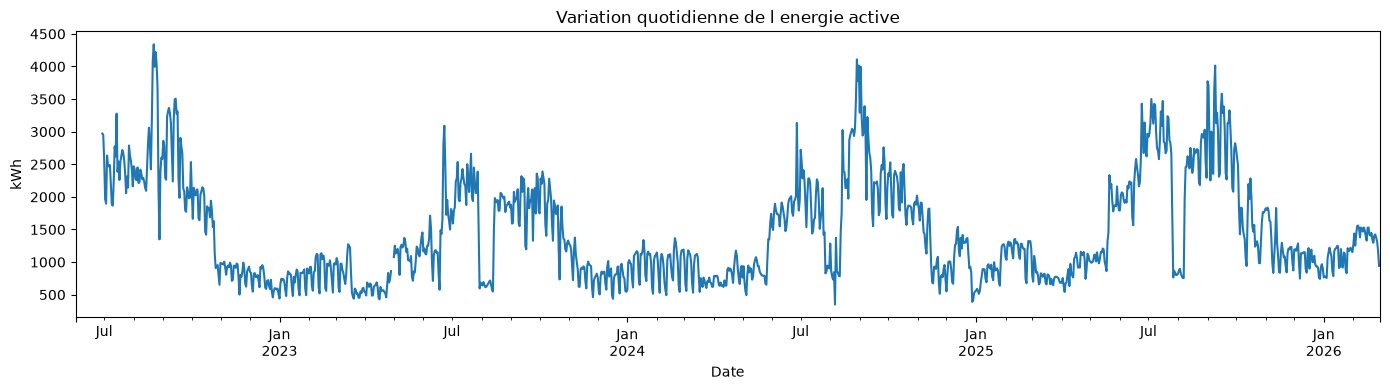

In [5]:
import matplotlib.pyplot as plt

energy_column = 'EM_VIRTUAL kWh (kWh) [ABS]'
daily_energy = (
    df.set_index('timestamp')[energy_column]
      .resample('D')
      .last()
      .diff()
      .rename('daily_energy_delta')
)

ax = daily_energy.plot(figsize=(14, 4), title='Variation quotidienne de l energie active')
ax.set_xlabel('Date')
ax.set_ylabel('kWh')
plt.tight_layout()
plt.show()